PHASE-1

In [23]:
import sqlite3
import pandas as pd

# Connect to database
conn = sqlite3.connect('/content/enterprise_database (1).db')

# Check tables
tables = pd.read_sql_query(
    "SELECT name FROM sqlite_master WHERE type='table';",
    conn
)

print(tables)

    name
0  users


In [24]:
query = """
SELECT user_id, name, status, updated_at
FROM (
    SELECT *,
           ROW_NUMBER() OVER (
               PARTITION BY user_id
               ORDER BY updated_at DESC
           ) AS rn
    FROM users
)
WHERE rn = 1
AND status = 'Active'
"""

df_active_users = pd.read_sql_query(query, conn)

print("Number of active users:", len(df_active_users))

df_active_users.head()

Number of active users: 14183


,user_id,name,status,updated_at
0,U-00001,User_U-00001,Active,2023-01-28 14:00:00
1,U-00003,User_U-00003,Active,2023-01-22 14:00:00
2,U-00005,User_U-00005,Active,2023-01-17 14:00:00
3,U-00006,User_U-00006,Active,2023-01-05 14:00:00
4,U-00007,User_U-00007,Active,2023-01-27 14:00:00


PHASE-2

In [25]:
# ============================================================
# PHASE 2: REGEX & UNSTRUCTURED DATA WRANGLING
# ============================================================

# Load server logs correctly
df_logs = pd.read_csv('/content/server_logs (1).txt')

# Rename the column
df_logs.columns = ['log']

# Remove ERROR rows
df_logs = df_logs[~df_logs['log'].str.contains('ERROR', na=False)]

# Fix the extra quotation marks in the raw log
df_logs['log'] = df_logs['log'].str.replace('""', '"', regex=False)
df_logs['log'] = df_logs['log'].str.strip('"')

# Extract Date, User ID, Product ID and Euro Value
extracted_data = df_logs['log'].str.extract(
    r'\[(?P<Date>\d{4}-\d{2}-\d{2})\s+\d{2}:\d{2}:\d{2}\].*?'
    r'payload=\{"u":"(?P<User_ID>U-\d+)",\s*'
    r'"item_code":"(?P<Product_ID>PRD-\d+)",\s*'
    r'"eur_val":(?P<Euro_Value>[\d.]+)\}'
)

# Convert Euro Value to number
extracted_data['Euro_Value'] = pd.to_numeric(
    extracted_data['Euro_Value'],
    errors='coerce'
)

# Remove failed extractions
extracted_data = extracted_data.dropna()

# Display result
print("Number of cleaned transactions:", len(extracted_data))
extracted_data.head()

Number of cleaned transactions: 94902


,Date,User_ID,Product_ID,Euro_Value
0,2023-03-15,U-19484,PRD-874,3404.44
2,2023-05-09,U-18932,PRD-905,3406.21
3,2023-10-21,U-15882,PRD-284,164.08
4,2023-01-10,U-22781,PRD-665,26.80
5,2023-05-23,U-13348,PRD-589,4964.77


PHASE-3

In [26]:
import pandas as pd
import re
import sqlite3
import matplotlib.pyplot as plt
import seaborn as sns

In [27]:
# Load exchange rate dataset
df_rates = pd.read_csv('/content/daily_exchange_rates (1).csv')

# Clean column names
df_rates.columns = df_rates.columns.str.strip()

# Clean transaction column names
extracted_data.columns = extracted_data.columns.str.strip()

# Convert dates
df_rates['Date'] = pd.to_datetime(df_rates['Date'])
extracted_data['Date'] = pd.to_datetime(extracted_data['Date'])

# Sort exchange rates
df_rates = df_rates.sort_values('Date')

# Forward-fill missing exchange rates
df_rates['EUR_to_USD'] = df_rates['EUR_to_USD'].ffill()

# Merge transactions with exchange rates
df_merged = extracted_data.merge(
    df_rates,
    on='Date',
    how='left'
)

# Merge with active users
df_final = df_merged.merge(
    df_active_users[['user_id', 'name']],
    left_on='User_ID',
    right_on='user_id',
    how='inner'
)

# Calculate USD Revenue
df_final['USD_Revenue'] = (
    df_final['Euro_Value'] * df_final['EUR_to_USD']
)

# Display result
print("Final number of transactions:", len(df_final))
print("Columns:", df_final.columns.tolist())

df_final.head()

Final number of transactions: 53899
Columns: ['Date', 'User_ID', 'Product_ID', 'Euro_Value', 'EUR_to_USD', 'user_id', 'name', 'USD_Revenue']


,Date,User_ID,Product_ID,Euro_Value,EUR_to_USD,user_id,name,USD_Revenue
0,2023-03-15,U-19484,PRD-874,3404.44,1.178232,U-19484,User_U-19484,4011.220772
1,2023-10-21,U-15882,PRD-284,164.08,1.075350,U-15882,User_U-15882,176.443420
2,2023-01-10,U-22781,PRD-665,26.80,1.127128,U-22781,User_U-22781,30.207030
3,2023-10-20,U-22062,PRD-363,48.63,1.075350,U-22062,User_U-22062,52.294268
4,2023-12-02,U-22146,PRD-223,960.60,1.066142,U-22146,User_U-22146,1024.135923


DASHBOARD

Monthly USD Revenue:
      Month   USD_Revenue
0   2023-01  1.284176e+07
1   2023-02  1.143613e+07
2   2023-03  1.234893e+07
3   2023-04  1.201538e+07
4   2023-05  1.233364e+07
5   2023-06  1.208436e+07
6   2023-07  1.244416e+07
7   2023-08  1.281273e+07
8   2023-09  1.222895e+07
9   2023-10  1.250133e+07
10  2023-11  1.258822e+07
11  2023-12  1.263902e+07

Top 5 Most Valuable Customers:
       user_id          name   USD_Revenue
3613   U-06582  User_U-06582  40050.988262
12937  U-23313  User_U-23313  39555.806629
2078   U-03805  User_U-03805  39529.945085
11066  U-20018  User_U-20018  38649.965242
3553   U-06489  User_U-06489  38629.142146


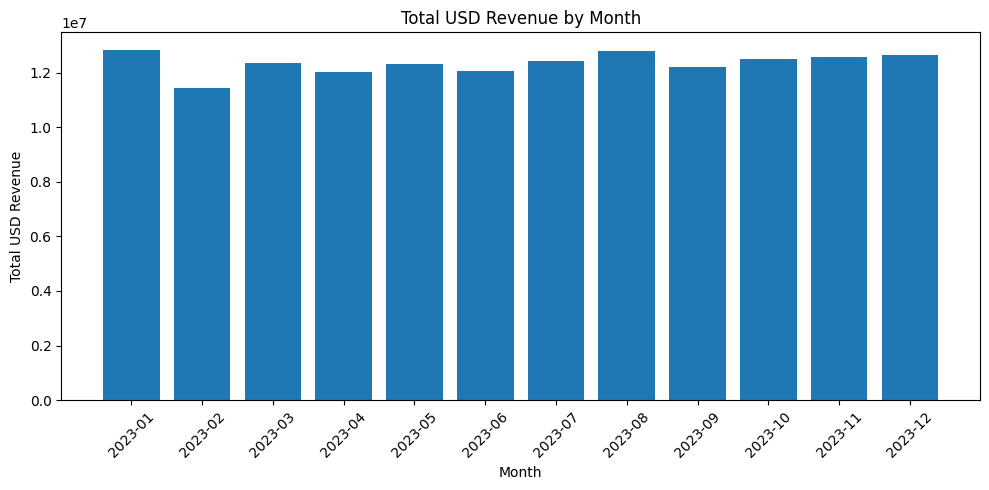

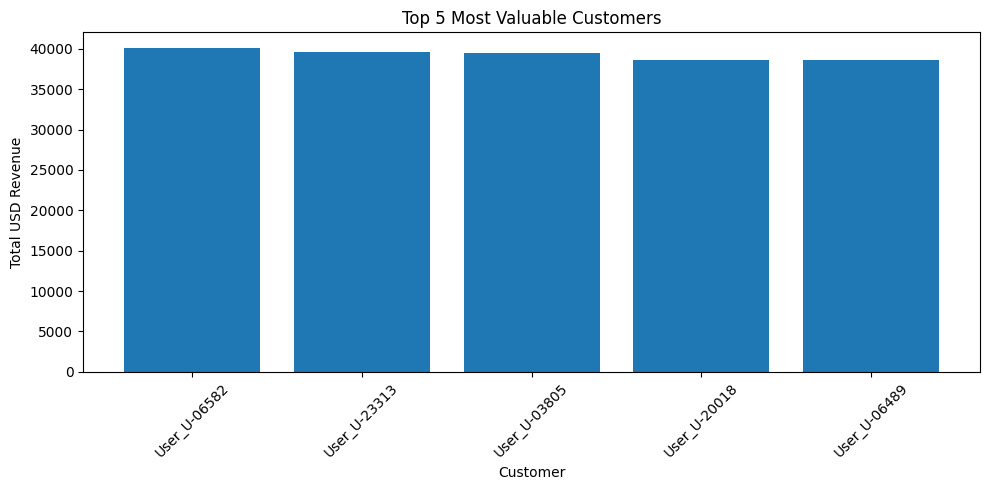

In [28]:
# PHASE 4: DASHBOARD

# Create Month column
df_final['Month'] = df_final['Date'].dt.to_period('M').astype(str)

# 1. Total USD Revenue by Month
monthly_revenue = (
    df_final.groupby('Month')['USD_Revenue']
    .sum()
    .reset_index()
)

print("Monthly USD Revenue:")
print(monthly_revenue)


# 2. Top 5 Most Valuable Customers
top_customers = (
    df_final.groupby(['user_id', 'name'])['USD_Revenue']
    .sum()
    .reset_index()
    .sort_values('USD_Revenue', ascending=False)
    .head(5)
)

print("\nTop 5 Most Valuable Customers:")
print(top_customers)


# 3. Monthly Revenue Chart
plt.figure(figsize=(10, 5))
plt.bar(monthly_revenue['Month'], monthly_revenue['USD_Revenue'])
plt.xticks(rotation=45)
plt.xlabel('Month')
plt.ylabel('Total USD Revenue')
plt.title('Total USD Revenue by Month')
plt.tight_layout()
plt.show()


# 4. Top 5 Customers Chart
plt.figure(figsize=(10, 5))
plt.bar(top_customers['name'], top_customers['USD_Revenue'])
plt.xticks(rotation=45)
plt.xlabel('Customer')
plt.ylabel('Total USD Revenue')
plt.title('Top 5 Most Valuable Customers')
plt.tight_layout()
plt.show()